# Model comparison and feature ablation

The full profile evaluates three sampled configurations per family with three stratified, group-aware CV folds. Average Precision is the search objective; ROC-AUC and Brier score are secondary diagnostics. Selection-set metrics choose among the refitted candidates. The final test is not involved.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
METRICS = ROOT / "reports" / "metrics"
FIGURES = ROOT / "reports" / "figures"
assert (METRICS / "final_test_metrics.json").exists(), "Run the full training CLI first."


def read_json(name):
    return json.loads((METRICS / name).read_text())


def show_figure(name):
    display(Image(filename=str(FIGURES / name)))

In [2]:
comparison = pd.read_csv(METRICS / "model_comparison.csv")
display(
    comparison[
        [
            "model",
            "average_precision",
            "roc_auc",
            "brier_score",
            "training_average_precision",
            "training_seconds",
        ]
    ]
)
for family in ["logistic", "forest", "catboost"]:
    print(family)
    display(
        pd.read_csv(METRICS / f"search_{family}.csv")[
            [
                "params",
                "mean_test_ap",
                "std_test_ap",
                "mean_test_auc",
                "mean_test_brier",
                "mean_train_ap",
            ]
        ]
    )

,model,average_precision,roc_auc,brier_score,training_average_precision,training_seconds
0,catboost_engineered,0.399490,0.860444,0.142299,0.440860,26.382261
1,catboost_raw,0.394880,0.860300,0.142565,0.440672,24.809696
2,forest_engineered,0.394357,0.859035,0.049655,0.422188,27.483670
3,forest_raw,0.392005,0.858680,0.049988,0.412732,25.000904
4,logistic_engineered,0.378707,0.854829,0.146019,0.383504,2.327091
5,logistic_raw,0.376165,0.852444,0.145901,0.382184,1.849352
6,dummy,0.067070,0.500000,0.062571,NaN,0.095051


logistic


,params,mean_test_ap,std_test_ap,mean_test_auc,mean_test_brier,mean_train_ap
0,"{'model__class_weight': None, 'model__C': 0.05}",0.377056,0.010566,0.849268,-0.050809,0.378118
1,"{'model__class_weight': 'balanced', 'model__C'...",0.382397,0.011522,0.853990,-0.145198,0.382663
2,"{'model__class_weight': 'balanced', 'model__C'...",0.382405,0.011522,0.853985,-0.145185,0.382689


forest


,params,mean_test_ap,std_test_ap,mean_test_auc,mean_test_brier,mean_train_ap
0,"{'model__n_estimators': 180, 'model__min_sampl...",0.390166,0.015322,0.860195,-0.049924,0.414874
1,"{'model__n_estimators': 180, 'model__min_sampl...",0.386971,0.014969,0.860950,-0.118309,0.475913
2,"{'model__n_estimators': 180, 'model__min_sampl...",0.385706,0.009365,0.858921,-0.049761,0.609023


catboost


,params,mean_test_ap,std_test_ap,mean_test_auc,mean_test_brier,mean_train_ap
0,"{'model__learning_rate': 0.06, 'model__l2_leaf...",0.377762,0.009814,0.858202,-0.050450,0.685680
1,"{'model__learning_rate': 0.06, 'model__l2_leaf...",0.381927,0.011787,0.852030,-0.118667,0.584357
2,"{'model__learning_rate': 0.03, 'model__l2_leaf...",0.390639,0.011009,0.859905,-0.130511,0.508312


## Feature engineering

Raw and engineered candidates share each family's chosen estimator parameters. CatBoost early stopping uses an internal training holdout, after which all training rows are used to refit. The engineered ablation reuses the resulting iteration count. Derived features summarize delinquency severity, utilization and income transforms, missingness, household income, and credit-line composition.

In [3]:
ablation = pd.read_csv(METRICS / "feature_ablation.csv")
display(ablation)
paired = ablation.pivot(index="family", columns="engineered", values="average_precision")
paired["AP_delta_engineered_minus_raw"] = paired[True] - paired[False]
display(paired)

,model,family,engineered,average_precision,roc_auc,brier_score,matched_model_parameters
0,logistic_raw,logistic,False,0.376165,0.852444,0.145901,True
1,logistic_engineered,logistic,True,0.378707,0.854829,0.146019,True
2,forest_raw,forest,False,0.392005,0.858680,0.049988,True
3,forest_engineered,forest,True,0.394357,0.859035,0.049655,True
4,catboost_raw,catboost,False,0.394880,0.860300,0.142565,True
5,catboost_engineered,catboost,True,0.399490,0.860444,0.142299,True


engineered,False,True,AP_delta_engineered_minus_raw
family,,,
catboost,0.394880,0.399490,0.004611
forest,0.392005,0.394357,0.002351
logistic,0.376165,0.378707,0.002541


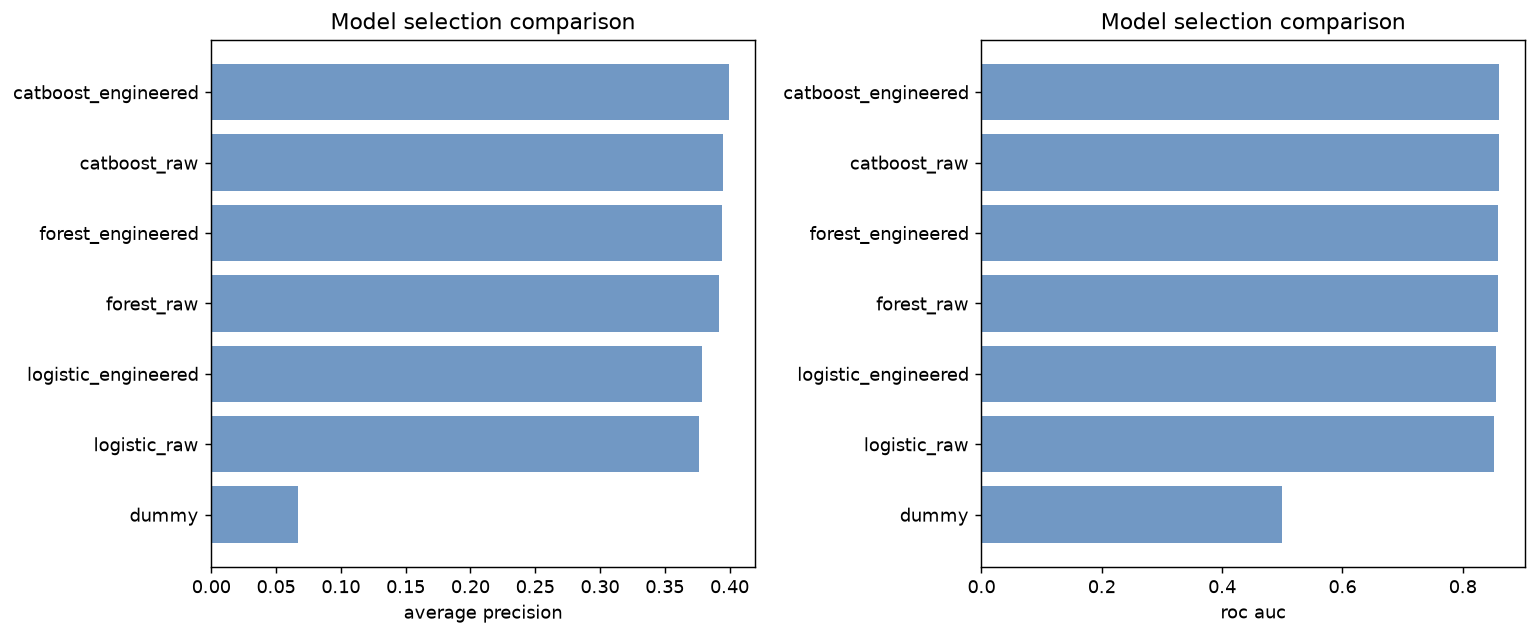

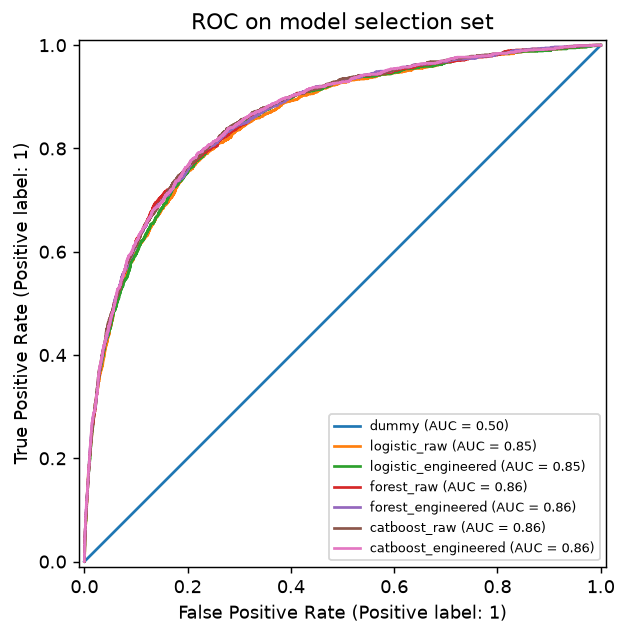

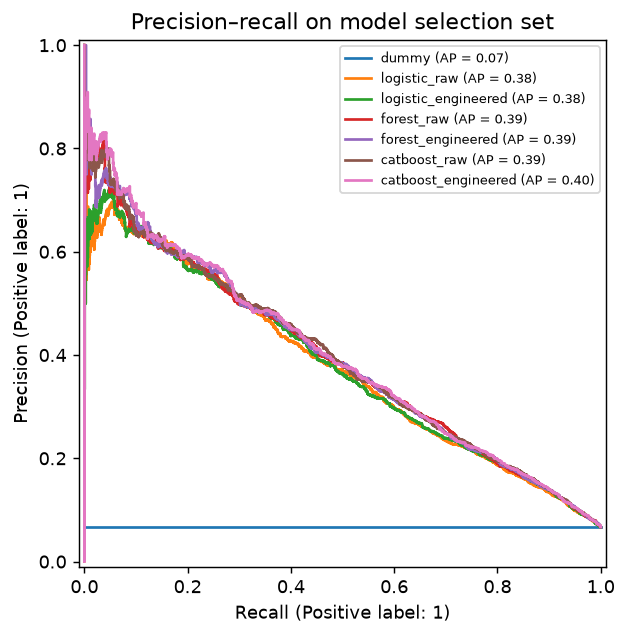

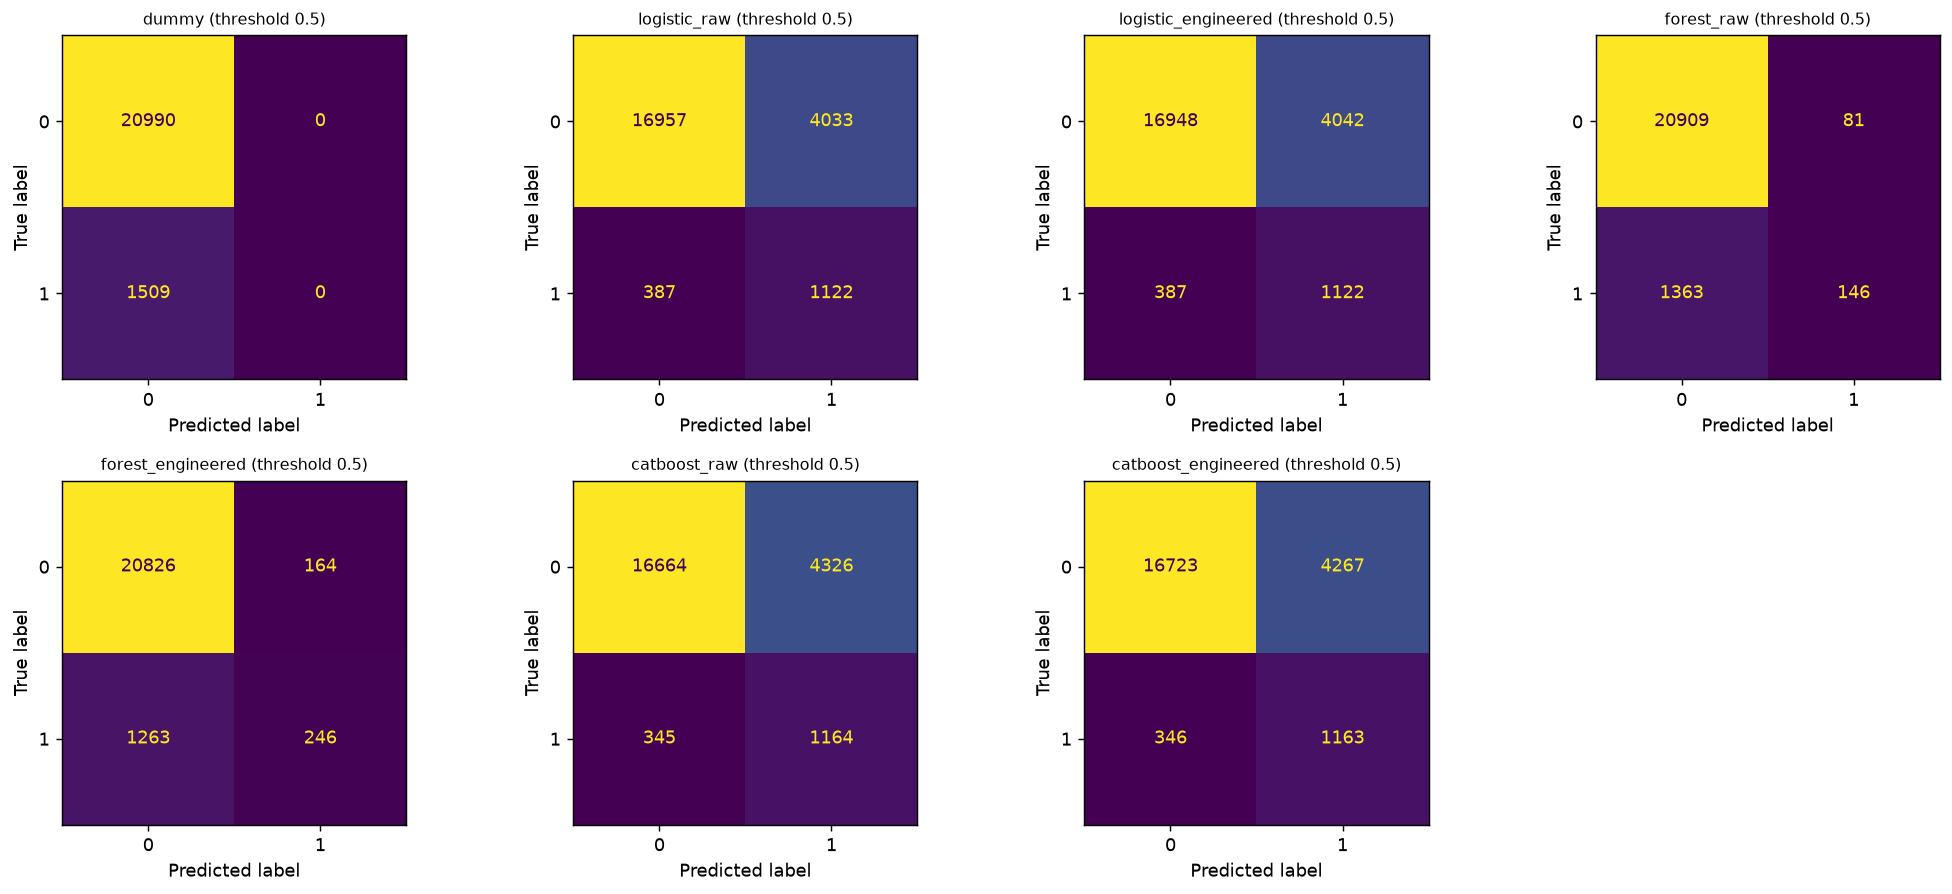

In [4]:
show_figure("model_comparison.png")
show_figure("roc_curves.png")
show_figure("precision_recall_curves.png")
show_figure("selection_confusion_matrices.png")

## Class weighting and overfitting

The matched-parameter weighting comparison uses fixed thresholds 0.5 and C_FP/(C_FP+C_FN), not thresholds tuned on the selection set. Compare recall with Brier score and conditional cost rather than treating recall alone as success. Training AP versus selection AP and CV variability are descriptive overfitting checks.

In [5]:
display(pd.read_csv(METRICS / "imbalance_comparison.csv", keep_default_na=False))
frozen = read_json("selection_frozen.json")
print(f"Selected: {frozen['model_name']}; engineered={frozen['feature_engineering']}.")
print(frozen["selection_rule"])
display(pd.Series(frozen["selected_parameters"]).to_frame("Selected parameter"))

,weighting,roc_auc,average_precision,precision,recall,f1,accuracy,balanced_accuracy,brier_score,log_loss,threshold,tn,fp,fn,tp,total_cost,cost_per_record,n_records,positive_rate
0,None,0.861938,0.399139,0.592369,0.195494,0.293971,0.937019,0.592911,0.049446,0.179410,0.500000,20787,203,1214,295,6273.0,0.278812,22499,0.06707
1,None,0.861938,0.399139,0.356427,0.542081,0.430074,0.903640,0.735857,0.049446,0.179410,0.166667,19513,1477,691,818,4932.0,0.219210,22499,0.06707
2,Balanced,0.860444,0.399490,0.214180,0.770709,0.335207,0.794969,0.783711,0.142299,0.447041,0.500000,16723,4267,346,1163,5997.0,0.266545,22499,0.06707
3,Balanced,0.860444,0.399490,0.106315,0.944997,0.191127,0.463532,0.686958,0.142299,0.447041,0.166667,9003,11987,83,1426,12402.0,0.551224,22499,0.06707


Selected: catboost_engineered; engineered=True.
Highest model-selection Average Precision; Brier score breaks ties


,Selected parameter
iterations,254
learning_rate,0.03
depth,8
l2_leaf_reg,8
loss_function,Logloss
thread_count,4
random_seed,42
verbose,False
auto_class_weights,Balanced
eval_metric,AUC


The final model is selected using observed selection AP, with Brier score as a tie-breaker. Ablation improvements are measured on one holdout and should not be interpreted as certain gains on future populations.